
Processing: i1.png


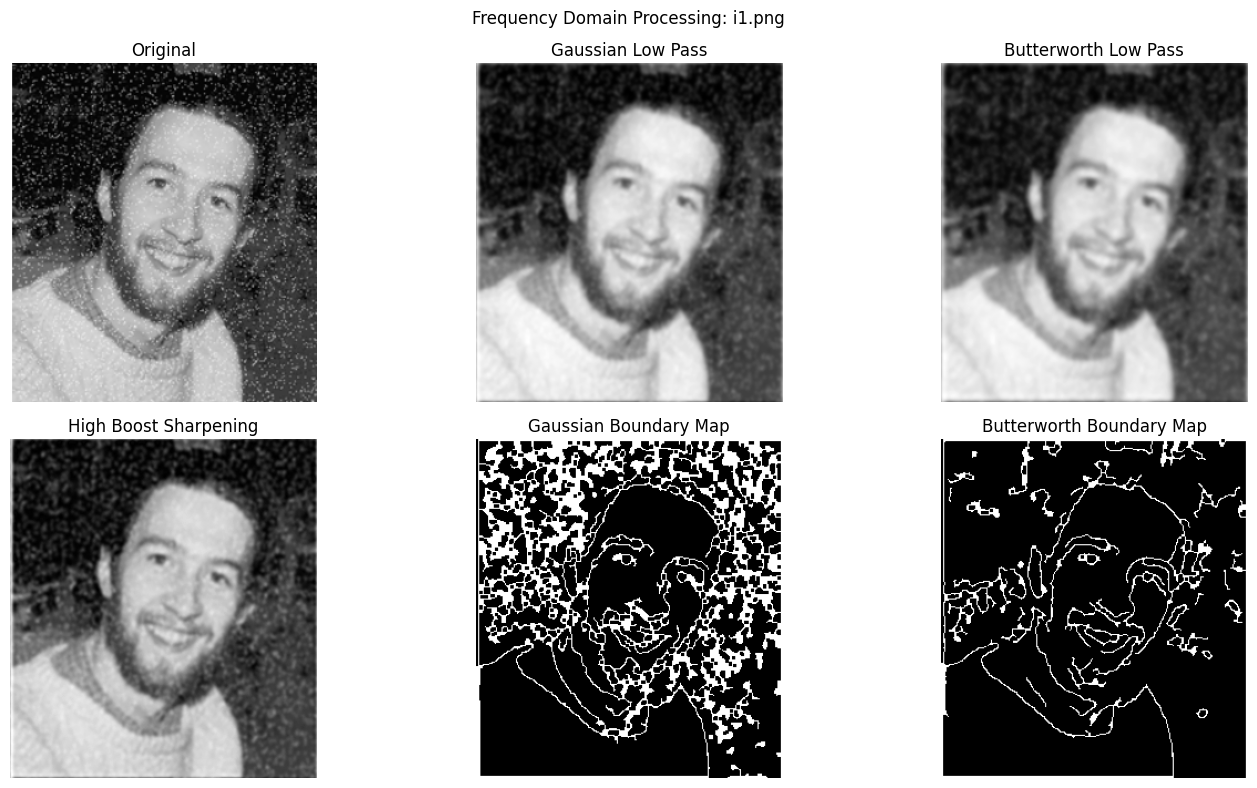


Processing: i2.png


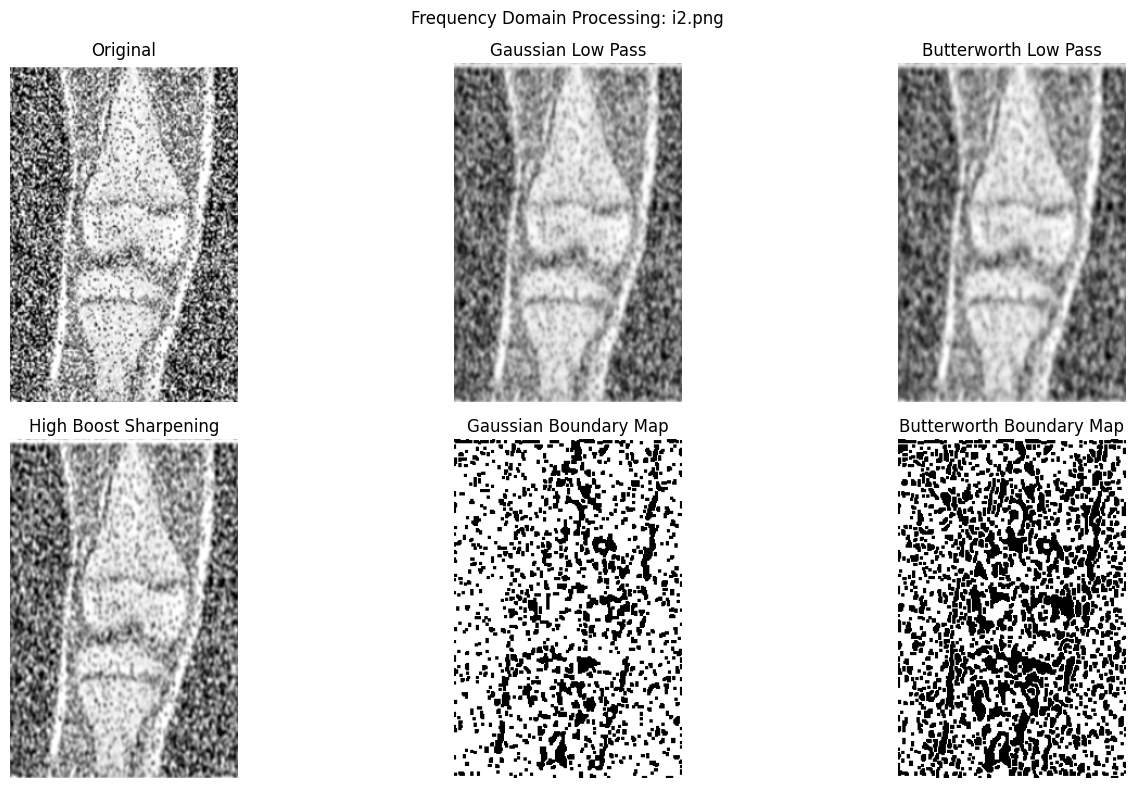


Processing: i3.png


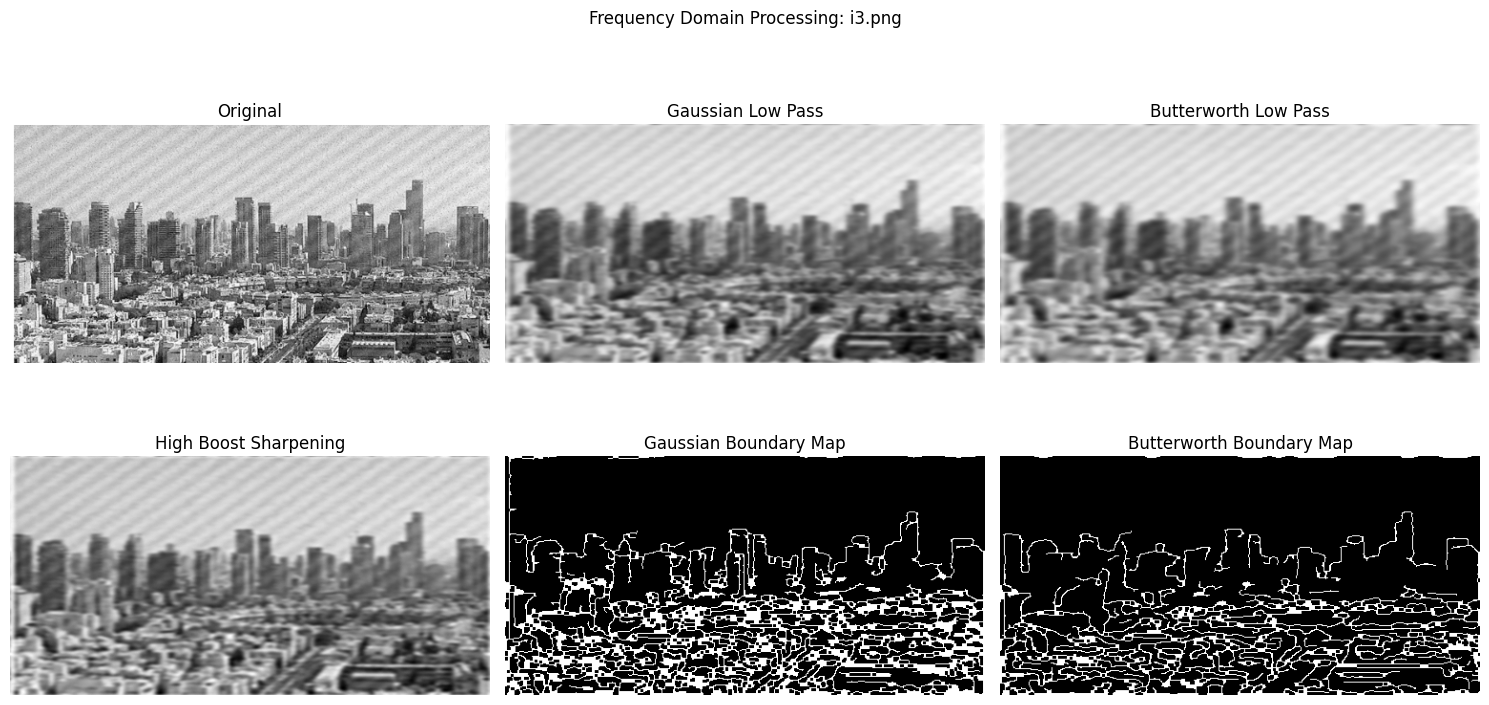


Processing: i4.png


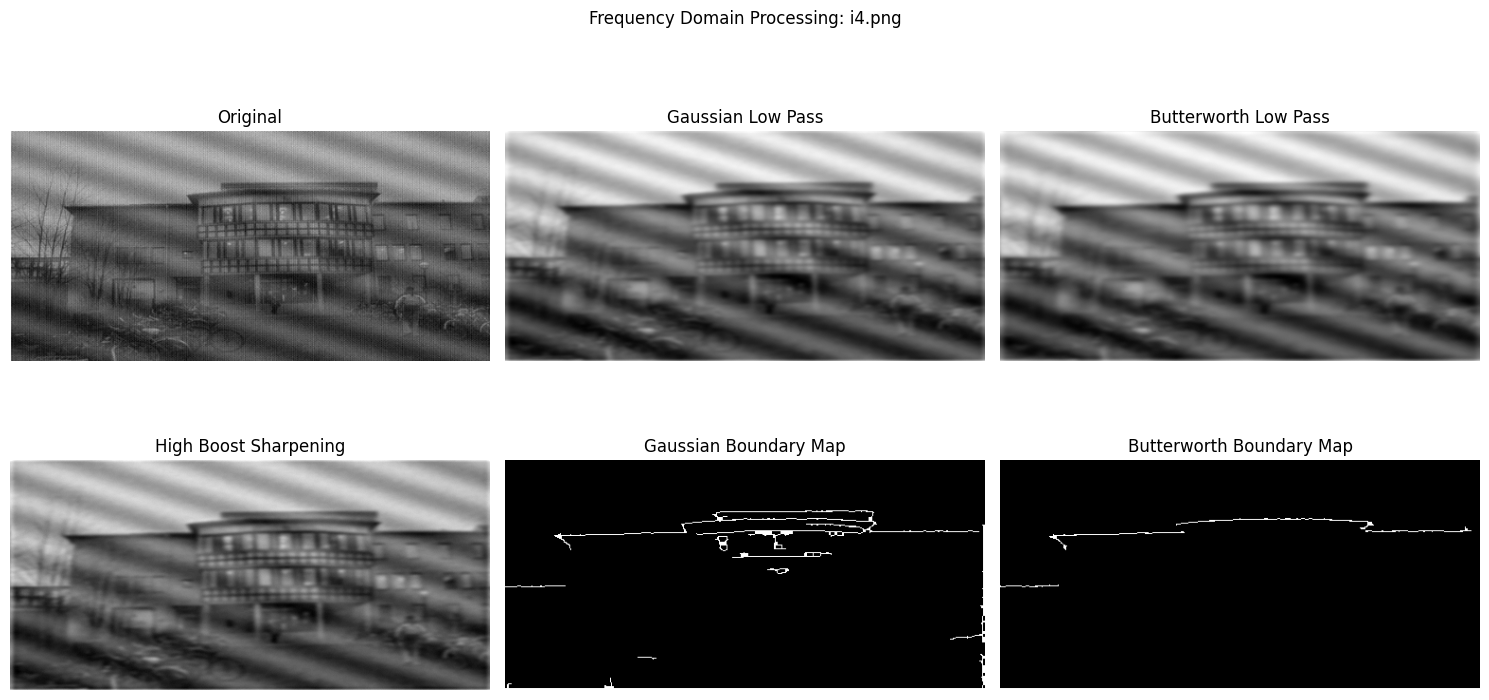


Processing: i5.png


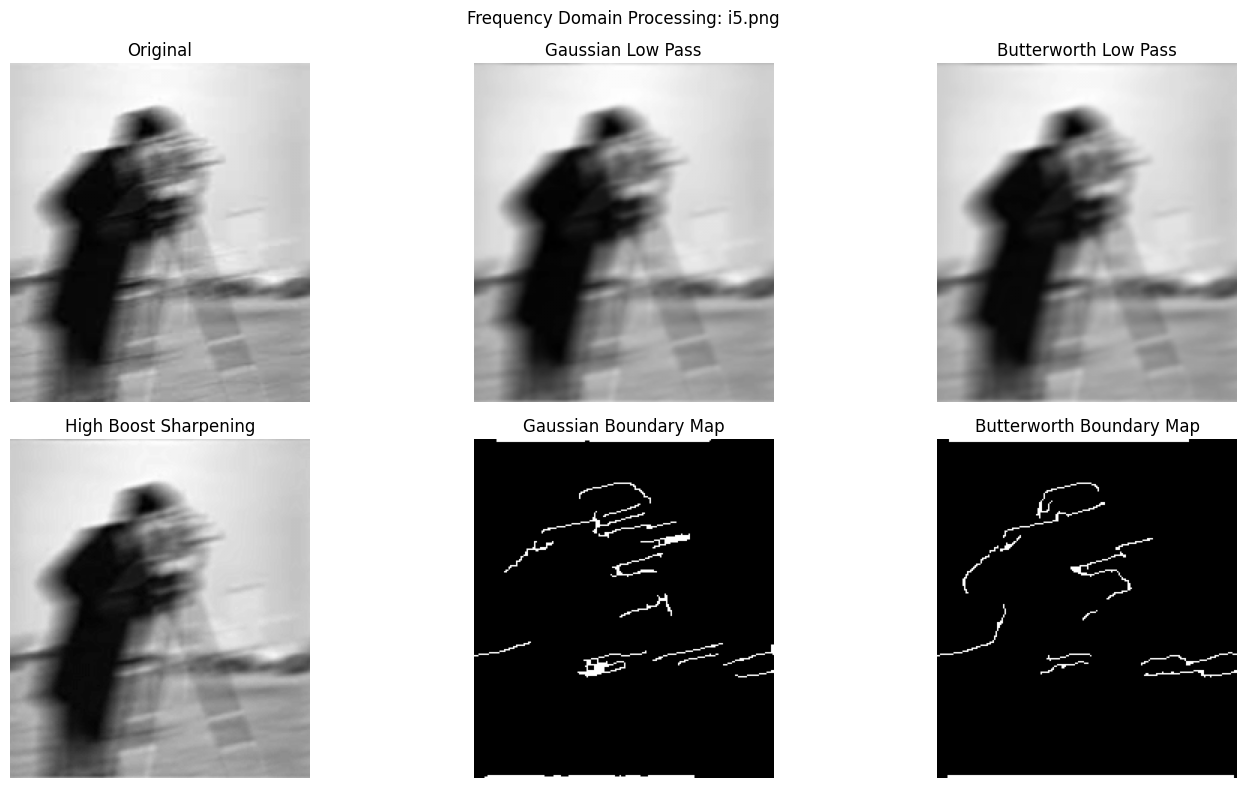


QUANTITATIVE RESULTS
 Image      Filter  Sharpness  Entropy  Edge Density  Intensity Variance
i1.png    Gaussian      72.76    7.495        0.0648             4840.70
i1.png Butterworth      49.70    7.499        0.0460             4877.57
i1.png  High Boost     191.88    7.587        0.2516             5096.48
i2.png    Gaussian     219.17    7.614        0.5398             2696.60
i2.png Butterworth     106.95    7.600        0.3505             2654.32
i2.png  High Boost     756.41    7.778        0.7175             3480.52
i3.png    Gaussian      38.91    7.152        0.0977             2200.92
i3.png Butterworth      24.80    7.166        0.0665             2212.54
i3.png  High Boost     119.18    7.317        0.1874             2559.61
i4.png    Gaussian      19.53    6.796        0.0097              981.91
i4.png Butterworth      14.78    6.815        0.0097              995.22
i4.png  High Boost      52.28    6.868        0.0252             1044.54
i5.png    Gaussian      14.19

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

# Create output folder
output_folder = "OPE10_Results"
os.makedirs(output_folder, exist_ok=True)

# Frequency Domain Gaussian Low Pass Filter
def gaussian_lowpass(shape, cutoff):
    rows, cols = shape
    crow, ccol = rows // 2, cols // 2

    u = np.arange(rows) - crow
    v = np.arange(cols) - ccol
    U, V = np.meshgrid(v, u)

    D = np.sqrt(U**2 + V**2)

    H = np.exp(-(D**2) / (2 * cutoff**2))
    return H


# Frequency Domain Butterworth Low Pass Filter
def butterworth_lowpass(shape, cutoff, order=2):
    rows, cols = shape
    crow, ccol = rows // 2, cols // 2

    u = np.arange(rows) - crow
    v = np.arange(cols) - ccol
    U, V = np.meshgrid(v, u)

    D = np.sqrt(U**2 + V**2)

    H = 1 / (1 + (D / cutoff)**(2 * order))
    return H


# Apply Frequency Domain Filter
def apply_filter(image, H):
    F = np.fft.fft2(image)
    F_shift = np.fft.fftshift(F)

    filtered = F_shift * H

    F_ishift = np.fft.ifftshift(filtered)
    img_back = np.fft.ifft2(F_ishift)

    img_back = np.abs(img_back)

    return np.uint8(np.clip(img_back, 0, 255))


# Frequency Domain High-Boost Sharpening
def highboost_filter(image, cutoff=30, boost=1.5):
    rows, cols = image.shape

    H_low = gaussian_lowpass(image.shape, cutoff)

    # High frequency mask
    H_high = 1 - H_low

    # High boost filter
    H = 1 + boost * H_high

    F = np.fft.fft2(image)
    F_shift = np.fft.fftshift(F)

    sharpened = F_shift * H

    F_ishift = np.fft.ifftshift(sharpened)
    result = np.fft.ifft2(F_ishift)

    return np.uint8(np.clip(np.abs(result), 0, 255))


# Boundary Detection
def detect_boundaries(image):
    # Canny edge detection
    edges = cv2.Canny(image, 50, 150)

    # Remove small gaps
    kernel = np.ones((3, 3), np.uint8)
    edges = cv2.morphologyEx(
        edges, cv2.MORPH_CLOSE, kernel
    )

    return edges


# Calculate Image Quality Metrics
def calculate_metrics(image, edges):
    sharpness = cv2.Laplacian(
        image, cv2.CV_64F
    ).var()

    entropy = cv2.calcHist(
        [image], [0], None, [256], [0, 256]
    ).flatten()

    entropy = entropy / entropy.sum()
    entropy = -np.sum(
        entropy[entropy > 0] *
        np.log2(entropy[entropy > 0])
    )

    edge_density = np.count_nonzero(edges) / edges.size

    intensity_variance = np.var(image)

    return sharpness, entropy, edge_density, intensity_variance


# Load all five images
image_names = [
    "i1.png",
    "i2.png",
    "i3.png",
    "i4.png",
    "i5.png"
]

results = []

for name in image_names:

    if not os.path.exists(name):
        print("Image not found:", name)
        continue

    # Read image in grayscale
    original = cv2.imread(name, cv2.IMREAD_GRAYSCALE)

    if original is None:
        print("Cannot read:", name)
        continue

    print("\nProcessing:", name)

    # 1. Gaussian Low Pass Filtering
    gaussian = apply_filter(
        original,
        gaussian_lowpass(original.shape, 30)
    )

    # 2. Butterworth Low Pass Filtering
    butterworth = apply_filter(
        original,
        butterworth_lowpass(original.shape, 30, 2)
    )

    # 3. High Boost Sharpening
    sharpened = highboost_filter(
        gaussian, cutoff=30, boost=1.5
    )

    # 4. Boundary Detection
    boundaries = detect_boundaries(sharpened)

    # Also detect boundaries using Butterworth output
    butter_edges = detect_boundaries(
        highboost_filter(butterworth)
    )

    # Save processed images
    folder_name = os.path.splitext(name)[0]
    save_path = os.path.join(output_folder, folder_name)
    os.makedirs(save_path, exist_ok=True)

    cv2.imwrite(save_path + "/original.png", original)
    cv2.imwrite(save_path + "/gaussian_filtered.png", gaussian)
    cv2.imwrite(save_path + "/butterworth_filtered.png", butterworth)
    cv2.imwrite(save_path + "/highboost_sharpened.png", sharpened)
    cv2.imwrite(save_path + "/gaussian_boundaries.png", boundaries)
    cv2.imwrite(save_path + "/butterworth_boundaries.png", butter_edges)

    # Calculate quantitative metrics
    for filter_name, processed, edge in [
        ("Gaussian", gaussian, detect_boundaries(gaussian)),
        ("Butterworth", butterworth, detect_boundaries(butterworth)),
        ("High Boost", sharpened, boundaries)
    ]:

        sharp, ent, density, variance = calculate_metrics(
            processed, edge
        )

        results.append({
            "Image": name,
            "Filter": filter_name,
            "Sharpness": round(sharp, 2),
            "Entropy": round(ent, 3),
            "Edge Density": round(density, 4),
            "Intensity Variance": round(variance, 2)
        })

    # Display results
    plt.figure(figsize=(15, 8))

    images = [
        original,
        gaussian,
        butterworth,
        sharpened,
        boundaries,
        butter_edges
    ]

    titles = [
        "Original",
        "Gaussian Low Pass",
        "Butterworth Low Pass",
        "High Boost Sharpening",
        "Gaussian Boundary Map",
        "Butterworth Boundary Map"
    ]

    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i], cmap="gray")
        plt.title(titles[i])
        plt.axis("off")

    plt.suptitle("Frequency Domain Processing: " + name)
    plt.tight_layout()

    plt.savefig(save_path + "/comparison.png")
    plt.show()


# Display quantitative comparison
df = pd.DataFrame(results)

print("\nQUANTITATIVE RESULTS")
print(df.to_string(index=False))

# Save results as CSV
df.to_csv(
    os.path.join(output_folder, "filter_comparison.csv"),
    index=False
)

print("\nAll processing completed successfully!")
print("Results saved in:", output_folder)
